## Qubit Power Fit with Fano Interference

Global complex fit of the waveguide-qubit power sweep following Appendix G of
[Sandbo Chang et al., arXiv:2503.07559](https://arxiv.org/abs/2503.07559), eq. (G.1):

$$t = 1 - e^{i\theta_F}\,\frac{\xi\Gamma_1}{2\Gamma_2}\,
\frac{1 - i\Delta/\Gamma_2}{1 + (\Delta/\Gamma_2)^2 + \Omega^2/\Gamma_1\Gamma_2},
\qquad \Gamma_2 = \Gamma_1/2 + \Gamma_\phi,\quad
P = \frac{\hbar\omega_q\Omega^2}{2\Gamma_1},\quad P_\mathrm{RT} = A_\mathrm{sys} P$$

with $\Delta = \omega_q - \omega_p$. As in the paper, $\xi = 1$, the data are normalized to the saturated high-power trace, and Re and Im are fitted together, so the system attenuation $A_\mathrm{sys}$ is a direct fit parameter.
A constant complex background is added for imperfect normalization.

| code | symbol | unit |
|---|---|---|
| `f0` | $\omega_q/2\pi$ | GHz |
| `g1` | $\Gamma_1/2\pi$ | MHz |
| `gphi` | $\Gamma_\phi/2\pi$ | MHz |
| `att_db` | $A_\mathrm{sys}$ (VNA port to qubit) | dB |
| `theta_f` | $\theta_F$ | rad |
| `bg_re`, `bg_im` | background on $r = 1 - t$ | |

Helper functions are in `qubit_power_fit.py`; `qubit_power_fit.ipynb` is the plain Lorentzian (Re r) version.

In [1]:
%load_ext autoreload
%autoreload 2

from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

import qubit_power_fit as qpf

### Settings

* `CONJUGATE`: the model has Im r > 0 above resonance (as in the paper); our VNA data has the opposite sign, so r is conjugated before fitting. With the wrong sign the complex fit does not converge.
* `FIXED` holds parameters at a value, e.g. `{"bg_re": 0, "bg_im": 0}` to fit without background as in the paper.
* `F_RANGE = None` fits the whole scan, as in the paper.

In [3]:
DATA_FILE = Path("qubit-power-sweep-5_58GHz_fine.json")
REF_FILE = None            # qubit-detuned sweep; None: normalize by the highest-power trace
REF_POWER_DBM = None       # reference trace power when REF_FILE is None (None: highest power)
CONJUGATE = True

F_RANGE = None             # (min, max) GHz, None: all
FIT_POWER_RANGE = None     # (min, max) dBm, None: all
USE_WEIGHTS = True
XI = 1.0
FIXED = {}

ATT_POWER_RANGE = (-36, -20)  # dBm, points for the eq. 4 cross-check slope
R_ON_WINDOW_MHZ = 0.0

OUT_DIR = Path("results") / f"{DATA_FILE.stem}-fano"
OUT_DIR.mkdir(parents=True, exist_ok=True)

def save(fig, name):
    path = OUT_DIR / f"{DATA_FILE.stem}-fano-{name}.png"
    fig.savefig(path, dpi=150, bbox_inches="tight")
    print("saved", path)

### Load and normalize

In [4]:
sweep = qpf.load_sweep(DATA_FILE)

if REF_FILE is None:
    ref, p_norm = qpf.reference_trace(sweep, REF_POWER_DBM)
    ref_label = f"trace at {p_norm:g} dBm"
else:
    ref, p_norm = qpf.load_sweep(REF_FILE), None
    ref_label = str(REF_FILE)

r = 1 - qpf.normalize(sweep, ref)
if CONJUGATE:
    r = np.conj(r)
noise = qpf.trace_noise(r)

print(f"file        : {sweep.path}  ({sweep.meta.get('date')} {sweep.meta.get('time')})")
print(f"shape       : {sweep.s21.shape}  (powers, frequencies)")
print(f"frequency   : {sweep.fghz[0]:.4f} - {sweep.fghz[-1]:.4f} GHz")
print(f"power       : {sweep.power_dbm.min():g} - {sweep.power_dbm.max():g} dBm")
print(f"attenuator  : {sweep.attenuator_db} dB (warm programmable)")
print(f"reference   : {ref_label}, conjugated: {CONJUGATE}")

file        : qubit-power-sweep-5_58GHz_fine.json  (14-10-2026 06:59:48)
shape       : (51, 401)  (powers, frequencies)
frequency   : 5.4000 - 5.8000 GHz
power       : -50 - 0 dBm
attenuator  : 25.0 dB (warm programmable)
reference   : trace at 0 dBm, conjugated: True


saved results\qubit-power-sweep-5_58GHz_fine-fano\qubit-power-sweep-5_58GHz_fine-fano-re-im-traces.png


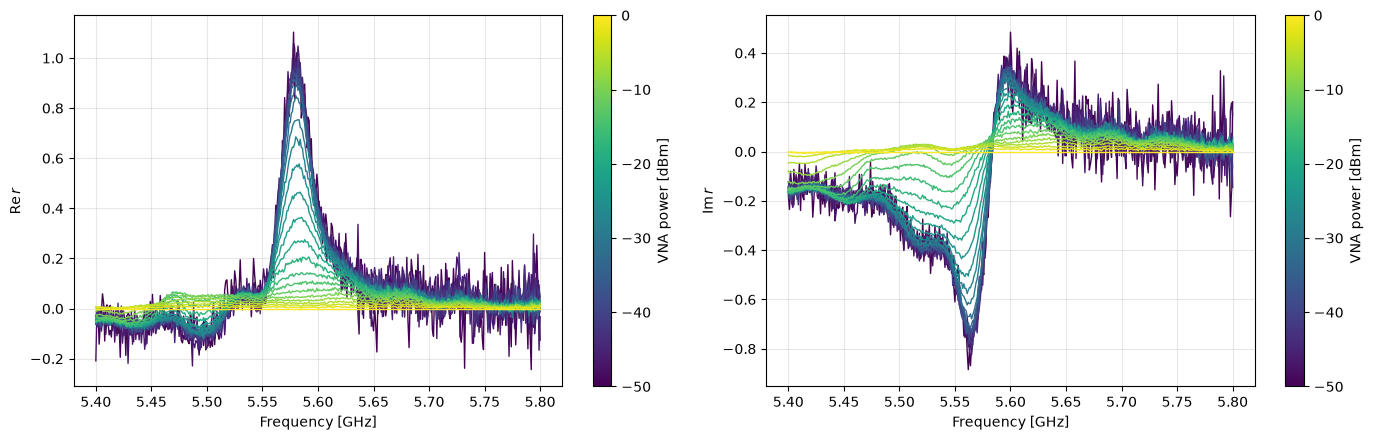

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
qpf.plot_traces(sweep.fghz, sweep.power_dbm, r.real, every=2, ylabel=r"$\mathrm{Re}\,r$", ax=axes[0])
qpf.plot_traces(sweep.fghz, sweep.power_dbm, r.imag, every=2, ylabel=r"$\mathrm{Im}\,r$", ax=axes[1])
fig.tight_layout()
save(fig, "re-im-traces")
plt.show()

### Fano fit

In [6]:
fit = qpf.fit_fano(
    sweep.fghz, sweep.power_dbm, r,
    p_norm=p_norm, xi=XI, f_range=F_RANGE, power_range=FIT_POWER_RANGE,
    sigma=noise if USE_WEIGHTS else None, fixed=FIXED,
)
print(fit.report())

q = qpf.qubit_params(fit)
print()
print(f"Gamma2/2π      = {q['g2']:.4f} MHz")
print(f"A_sys          = {fit['att_db']:.2f} ± {fit.err('att_db'):.2f} dB")
if sweep.attenuator_db is not None:
    print(f"  without {sweep.attenuator_db:g} dB programmable attenuator: {fit['att_db'] - sweep.attenuator_db:.2f} dB")

          f0 = 5.574197 ± 8.3e-05 GHz
          g1 = 33.99479 ± 0.1 MHz
        gphi = 2.333375e-13 ± 0.076 MHz
      att_db = 101.0287 ± 0.039 dB
     theta_f = -0.3710101 ± 0.0027 rad
       bg_re = 0.00659022 ± 0.00017
       bg_im = 0.002211676 ± 0.00017
   rms resid = 0.0504
    chi2_red = 40.7

Gamma2/2π      = 16.9974 MHz
A_sys          = 101.03 ± 0.04 dB
  without 25 dB programmable attenuator: 76.03 dB


saved results\qubit-power-sweep-5_58GHz_fine-fano\qubit-power-sweep-5_58GHz_fine-fano-maps.png


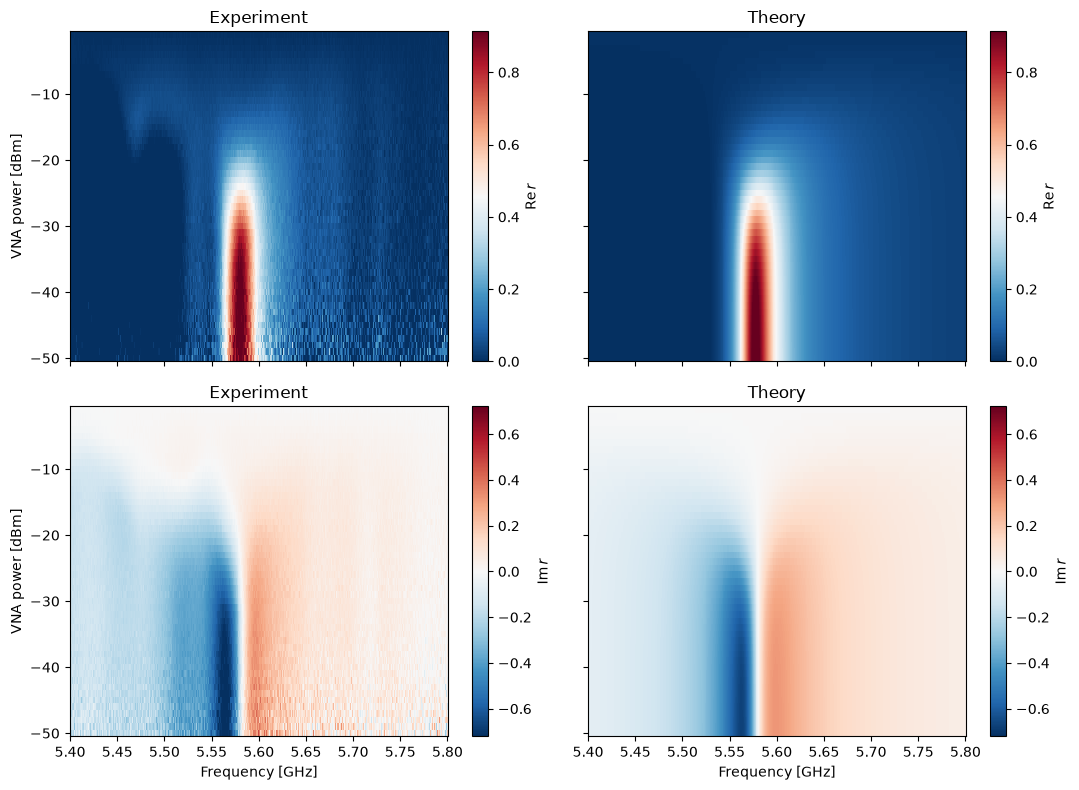

saved results\qubit-power-sweep-5_58GHz_fine-fano\qubit-power-sweep-5_58GHz_fine-fano-fit.png


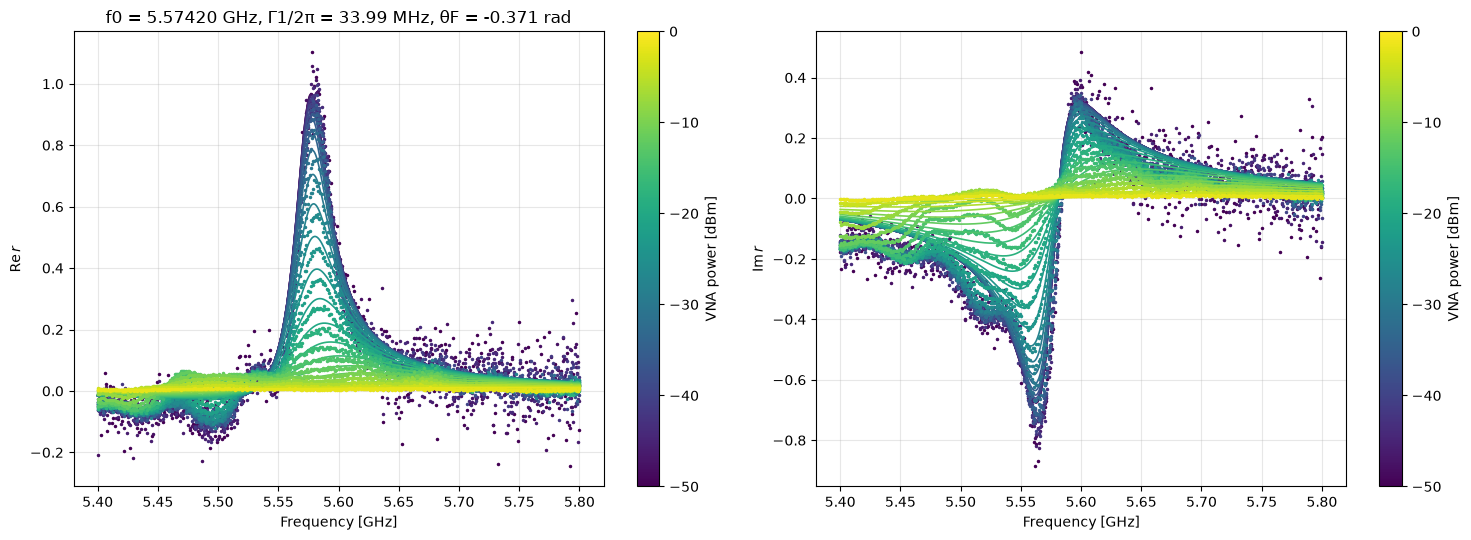

saved results\qubit-power-sweep-5_58GHz_fine-fano\qubit-power-sweep-5_58GHz_fine-fano-fit-residuals.png


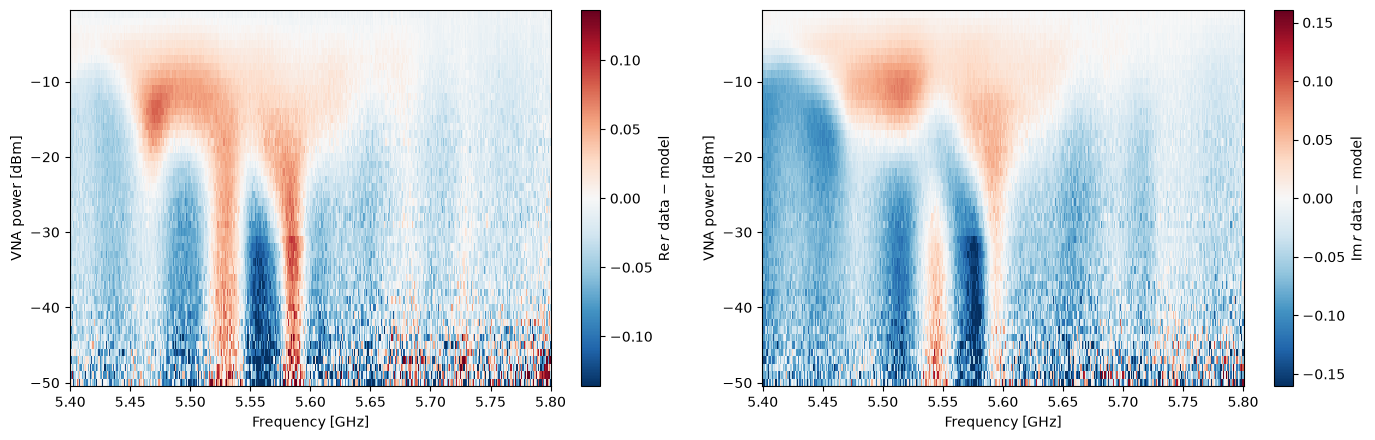

saved results\qubit-power-sweep-5_58GHz_fine-fano\qubit-power-sweep-5_58GHz_fine-fano-power-cut.png


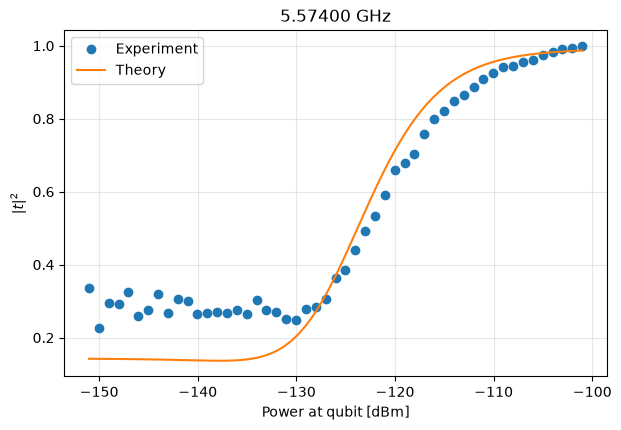

In [7]:
fig = qpf.plot_fit_maps(fit, sweep.fghz, sweep.power_dbm, r)
save(fig, "maps")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
qpf.plot_fit(fit, sweep.fghz, sweep.power_dbm, r, every=2, part="real", ax=axes[0])
qpf.plot_fit(fit, sweep.fghz, sweep.power_dbm, r, every=2, part="imag", ax=axes[1])
axes[0].set_title(f"f0 = {fit['f0']:.5f} GHz, Γ1/2π = {fit['g1']:.2f} MHz, θF = {fit['theta_f']:.3f} rad")
fig.tight_layout()
save(fig, "fit")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
qpf.plot_fit_residuals(fit, sweep.fghz, sweep.power_dbm, r, part="real", ax=axes[0])
qpf.plot_fit_residuals(fit, sweep.fghz, sweep.power_dbm, r, part="imag", ax=axes[1])
fig.tight_layout()
save(fig, "fit-residuals")
plt.show()

fig = qpf.plot_power_cut(fit, sweep.fghz, sweep.power_dbm, r, att_db=fit["att_db"])
save(fig, "power-cut")
plt.show()

### Comparison

Same complex fit with $\theta_F = 0$ (no Fano), and the plain Lorentzian fit of Re r from `qubit_power_fit.ipynb`.
χ² of the Re-only fit is not directly comparable to the complex fits.

In [8]:
fit_no_fano = qpf.fit_fano(
    sweep.fghz, sweep.power_dbm, r,
    p_norm=p_norm, xi=XI, f_range=F_RANGE, power_range=FIT_POWER_RANGE,
    sigma=noise if USE_WEIGHTS else None, fixed={**FIXED, "theta_f": 0.0},
)
fit_re = qpf.fit_power_sweep(
    sweep.fghz, sweep.power_dbm, r.real, p_ref=-30.0, p_norm=p_norm,
    f_range=(5.56, 5.60), sigma=qpf.trace_noise(r.real) if USE_WEIGHTS else None,
)

rows = []
for label, ft in [("Fano (complex)", fit), ("θF = 0 (complex)", fit_no_fano), ("Lorentzian (Re r)", fit_re)]:
    qq = qpf.qubit_params(ft)
    rows.append((label, qq["f0"], qq["g1"], qq["g2"], ft["theta_f"] if "theta_f" in ft.names else 0.0,
                 qq["att_db"], ft.chi2_red if ft.chi2_red is not None else float("nan")))

print(f"{'model':<20}{'f0 [GHz]':>11}{'Γ1/2π':>9}{'Γ2/2π':>9}{'θF':>8}{'A [dB]':>9}{'chi2_red':>10}")
for row in rows:
    print(f"{row[0]:<20}{row[1]:>11.5f}{row[2]:>9.3f}{row[3]:>9.3f}{row[4]:>8.3f}{row[5]:>9.2f}{row[6]:>10.2f}")

model                  f0 [GHz]    Γ1/2π    Γ2/2π      θF   A [dB]  chi2_red
Fano (complex)          5.57420   33.995   16.997  -0.371   101.03     40.71
θF = 0 (complex)        5.58122   31.713   15.857   0.000   101.19     58.67
Lorentzian (Re r)       5.58157   28.816   14.663   0.000   103.36      7.40


### Attenuation cross-check

Per-power $W_0$ from on-resonance r (eq. 4 of Hönigl-Decrinis 2020), after removing the fitted background and $e^{i\theta_F}$, compared with $A_\mathrm{sys}$ from the global fit.

A_sys (global fit)        = 101.03 dB
Attenuation (eq. 4 slope) = 102.03 dB
saved results\qubit-power-sweep-5_58GHz_fine-fano\qubit-power-sweep-5_58GHz_fine-fano-attenuation.png


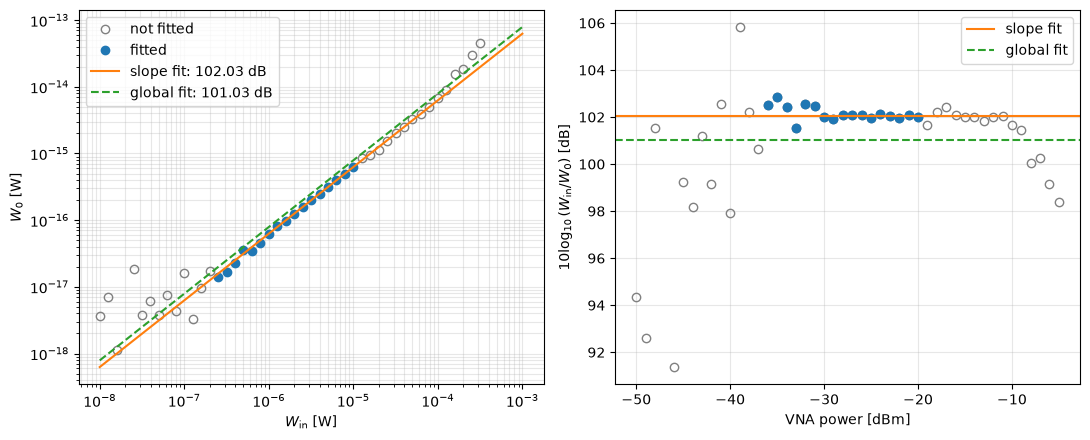

In [9]:
att = qpf.fit_attenuation(fit, sweep.fghz, sweep.power_dbm, r,
                          power_range=ATT_POWER_RANGE, window_mhz=R_ON_WINDOW_MHZ)
print(f"A_sys (global fit)        = {att.attenuation_fit_db:.2f} dB")
print(f"Attenuation (eq. 4 slope) = {att.attenuation_db:.2f} dB")

fig = qpf.plot_attenuation(att)
save(fig, "attenuation")
plt.show()

### Save results

In [9]:
results = {
    "data_file": str(DATA_FILE),
    "reference": ref_label,
    "conjugated": CONJUGATE,
    "timestamp": sweep.meta.get("timestamp"),
    "programmable_attenuator_db": sweep.attenuator_db,
    "settings": {
        "f_range_ghz": F_RANGE, "p_norm_dbm": p_norm, "xi": XI, "fixed": FIXED,
        "fit_power_range_dbm": FIT_POWER_RANGE, "use_weights": USE_WEIGHTS,
        "att_power_range_dbm": ATT_POWER_RANGE, "r_on_window_mhz": R_ON_WINDOW_MHZ,
    },
    "fit": fit.to_dict(),
    "gamma2_mhz": q["g2"],
    "fit_no_fano": fit_no_fano.to_dict(),
    "fit_lorentzian_re": fit_re.to_dict(),
    "attenuation": att.to_dict(),
}
qpf.save_json(OUT_DIR / f"{DATA_FILE.stem}-fano-fit-results.json", results)

WindowsPath('results/1791925995-qubit-power-sweep-fano/1791925995-qubit-power-sweep-fano-fit-results.json')